In [2]:
# CELL 1 — Setup and load the three CSV files.
# If imports fail, run this in a separate notebook cell: %pip install pandas numpy matplotlib
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

DATA_ROOT = Path("/Users/yoanayosifova/Desktop/codex-health/process_metrics/codex_activity")
# DATA_ROOT may also point directly to codex_activity/exports/<timestamp>.
if (DATA_ROOT / "manifest.json").exists():
    EXPORT = DATA_ROOT
else:
    latest = json.loads((DATA_ROOT / "latest.json").read_text())
    original = Path(latest["export_directory"])
    EXPORT = DATA_ROOT / "exports" / original.name
    if not EXPORT.exists():
        EXPORT = original

manifest = json.loads((EXPORT / "manifest.json").read_text())
if manifest.get("gaps") or manifest.get("collection_status") != "complete_for_api_visible_scope":
    raise ValueError("Collection is incomplete. Repair the gaps before plotting.")

contributors = pd.read_csv(EXPORT / "contributors_all.csv", dtype="string", keep_default_na=False)
response_summary = pd.read_csv(EXPORT / "response_period_summary.csv", dtype="string", keep_default_na=False)
workflow_summary = pd.read_csv(EXPORT / "workflow_period_counts.csv", dtype="string", keep_default_na=False)
for frame in [contributors, response_summary, workflow_summary]:
    if not frame["data_complete"].str.lower().eq("true").all():
        raise ValueError("An input CSV contains incomplete data.")
contributors["total_contributions"] = pd.to_numeric(contributors["total_contributions"])
response_summary["mean_response_hours"] = pd.to_numeric(response_summary["mean_response_hours"].replace("", np.nan))
workflow_summary["count"] = pd.to_numeric(workflow_summary["count"])
for frame in [response_summary, workflow_summary]:
    frame["period_start"] = pd.to_datetime(frame["period_start"], utc=True)

COLORS = {"other_user": "#2166ac", "bot": "#d97706", "any": "#15803d"}
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .15})
print("Loaded:", EXPORT)
print("Observation:", manifest["scope"]["start"], "to", manifest["scope"]["end"], "(end exclusive)")

Loaded: /Users/yoanayosifova/Desktop/codex-health/process_metrics/codex_activity/exports/20261023T050449-97395000
Observation: 2025-10-22T00:00:00Z to 2026-10-21T00:00:00Z (end exclusive)


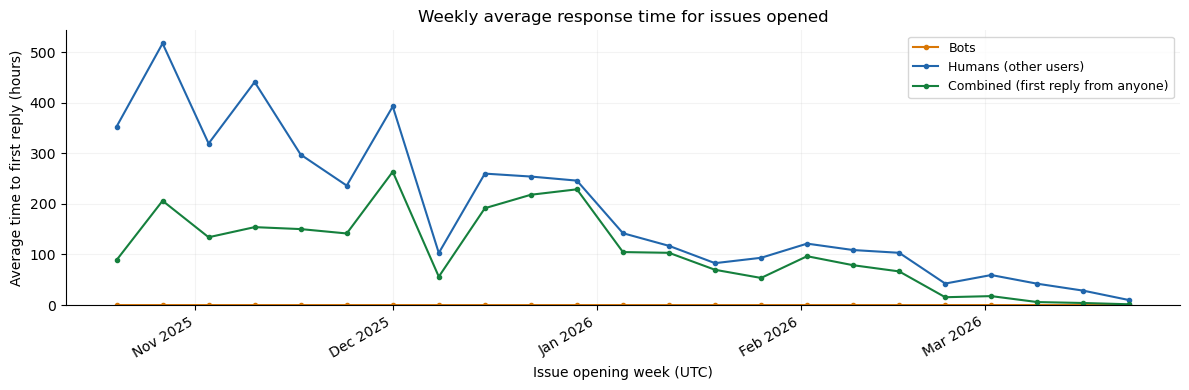

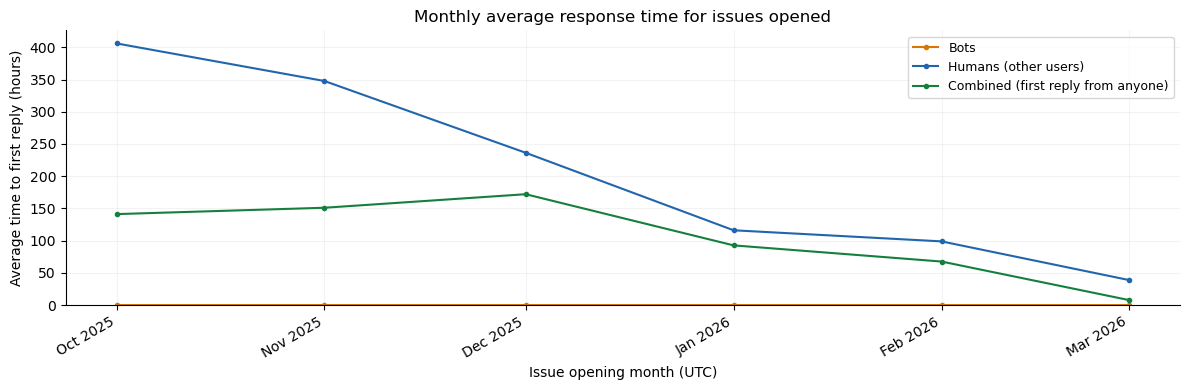

In [3]:
# CELL 3 — Two line plots: weekly and monthly average issue response times.
response_lines = [("bot", "Bots"), ("other_user", "Humans (other users)"), ("any", "Combined (first reply from anyone)")]
for grain, title in [("week", "Weekly"), ("month", "Monthly")]:
    subset = response_summary.loc[response_summary["period_type"].eq(grain)]
    # The collector already calculated means per opening-period and response class.
    # Keep missing means as NaN: no observed replies is not a zero-hour response.
    means = subset.pivot(index="period_start", columns="response_class", values="mean_response_hours").sort_index()
    fig, ax = plt.subplots(figsize=(12, 4))
    for label, name in response_lines:
        values = means[label] if label in means else pd.Series(np.nan, index=means.index)
        # ax.plot(means.index, values, marker="o", markersize=3, linewidth=1.5, color=COLORS[label], label=name)
        values = pd.to_numeric(values, errors="coerce").to_numpy(
            dtype=float,
            na_value=np.nan
        )

        ax.plot(
            means.index, values,
            marker="o", markersize=3, linewidth=1.5,
            color=COLORS[label], label=name
        )
        
    ax.set(title=f"{title} average response time for issues opened",
           xlabel=f"Issue opening {grain} (UTC)", ylabel="Average time to first reply (hours)")
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.legend(fontsize=9)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()